# OSMOS — Baseline d'entraînement ML pour la classification dynamique des prospects et clients

Ce notebook est une base de travail pour entraîner des modèles de Machine Learning sur le dataset simulé du projet **OSMOS Digital Twin**.

## Objectif

Prédire la classe dynamique d'un prospect/client à partir de son jumeau numérique :

- `Cold Prospect`
- `Warm Prospect`
- `Hot Prospect`
- `New Client`
- `Active Client`
- `VIP Client`
- `Dormant Client`
- `Churn Risk Client`
- `Upsell Candidate`
- `Cross-Sell Candidate`

## Données utilisées

Le notebook utilise principalement :

- `osmos_digital_twin_snapshots.csv` : scores, comportements, classe dynamique, action recommandée.
- `osmos_customers_prospects.csv` : informations de profil client/prospect.
- `osmos_events_stream.csv` : événements simulés, utilisé dans une section optionnelle.

> Place ce notebook dans le même dossier que le dossier `osmos_simulation_data`, ou adapte la variable `DATA_DIR` dans la cellule de chargement.


In [30]:
# ============================================================
# 1. Imports
# ============================================================

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)


## 2. Chargement des données

Cette cellule cherche automatiquement le dossier `osmos_simulation_data`.

Si tu exécutes le notebook ailleurs, modifie `DATA_DIR` manuellement.


In [ ]:
# ============================================================
# 2. Load data
# ============================================================

excel_path = Path("osmos_simulation_data.xlsx")

if not excel_path.exists():
    raise FileNotFoundError("Put osmos_simulation_data.xlsx in the same folder as this notebook.")

snapshots = pd.read_excel(excel_path, sheet_name="Digital_Twins")
profiles = pd.read_excel(excel_path, sheet_name="Customers")
events = pd.read_excel(excel_path, sheet_name="Events_Sample")
rules = pd.read_excel(excel_path, sheet_name="Action_Rules")

print("Snapshots:", snapshots.shape)
print("Profiles:", profiles.shape)
print("Events:", events.shape)
print("Rules:", rules.shape)

snapshots.head()


Snapshots: (1500, 25)
Profiles: (1500, 14)
Events: (5000, 12)
Rules: (9, 5)


,entity_id,entity_type,snapshot_date,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,dynamic_class,recommended_action
0,P00001,Prospect,2026-06-17,0.458,0.135,0.156,0.131,27,3,12,0,0,0.00,0.00,0.378,0.059,0,NaN,0,0.367,0.000,0.119,0.000,Cold Prospect,Continue awareness campaign
1,C00002,Client,2026-06-17,0.734,0.204,0.400,0.359,30,1,3,0,3,2974.47,991.49,0.328,0.039,1,2.78,1,0.505,0.542,1.000,0.396,Active Client,Send personalized product recommendation
2,C00003,Client,2026-06-17,0.440,0.607,0.638,0.345,12,17,74,13,6,3733.08,622.18,0.478,0.114,0,3.97,2,0.782,0.759,1.000,0.000,VIP Client,Send VIP loyalty reward
3,P00004,Prospect,2026-06-17,0.525,1.000,0.726,0.808,21,26,96,12,0,0.00,0.00,0.352,0.054,0,NaN,3,0.820,0.000,0.794,0.000,Hot Prospect,Send limited-time personalized offer
4,C00005,Client,2026-06-17,0.553,0.341,0.352,0.421,67,7,28,2,4,1747.41,436.85,0.517,0.091,0,4.24,2,0.053,0.411,1.000,0.510,Active Client,Send personalized product recommendation


In [57]:
# Aperçu des profils clients/prospects
profiles.head()

,entity_id,entity_type,created_at,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
0,P00001,Prospect,2025-09-12,Fès-Meknès,Facebook Ads,Student,Price Sensitive,18-24,Desktop,Electronics,True,0.957,0.285,0.135
1,C00002,Client,2025-10-20,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,True,0.367,0.736,0.115
2,C00003,Client,2026-05-14,Rabat-Salé-Kénitra,Marketplace App,B2C,Quality Seeker,35-44,Mobile,Home,True,0.792,0.138,0.613
3,P00004,Prospect,2025-09-02,Marrakech-Safi,Organic SEO,Family,Trend Follower,18-24,Desktop,Fashion,True,0.472,0.197,0.920
4,C00005,Client,2025-09-27,Casablanca-Settat,Referral,B2C,Quality Seeker,25-34,Mobile,Electronics,True,0.601,0.353,0.137


## 3. Compréhension rapide de la cible

La variable cible est :

```python
dynamic_class
```

Elle représente la classe marketing finale générée par le Digital Twin.


Classes disponibles:
dynamic_class
Warm Prospect        392
Hot Prospect         234
Active Client        225
Cold Prospect        193
Loyal Client         190
VIP Client           128
Churn Risk Client    121
New Client             9
Dormant Client         8
Name: count, dtype: int64


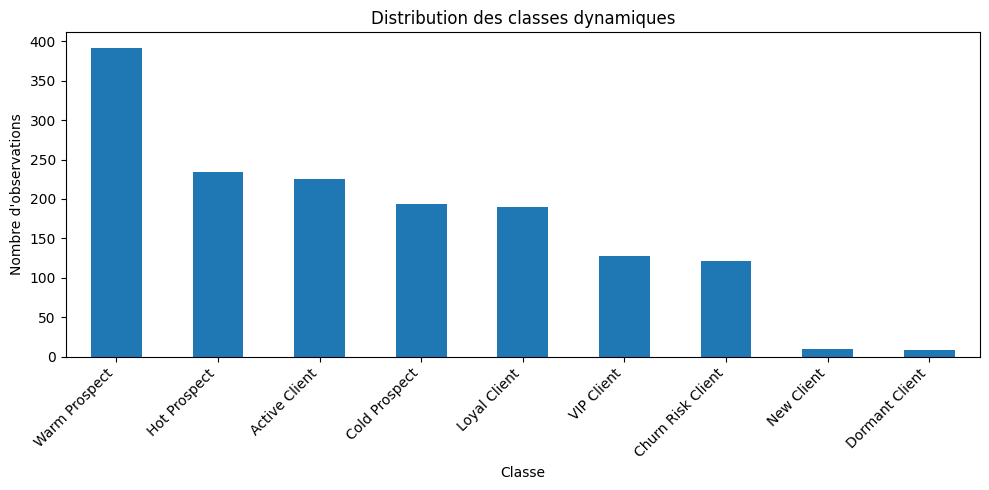

In [33]:
# ============================================================
# 3. Target distribution
# ============================================================

TARGET = "dynamic_class"

print("Classes disponibles:")
print(snapshots[TARGET].value_counts())

plt.figure(figsize=(10, 5))
snapshots[TARGET].value_counts().plot(kind="bar")
plt.title("Distribution des classes dynamiques")
plt.xlabel("Classe")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 4. Préparation du dataset d'entraînement

On fusionne :

- les snapshots Digital Twin ;
- les informations de profil client/prospect.

On supprime les colonnes qui ne doivent pas être utilisées directement comme variables prédictives :

- `dynamic_class` : cible à prédire ;
- `recommended_action` : action déjà déduite de la classe, donc fuite d'information ;
- identifiants et dates.


In [ ]:
# ============================================================
# 4. Merge snapshots + profiles
# ============================================================

df = snapshots.merge(
    profiles,
    on=["entity_id", "entity_type"],
    how="left",
    suffixes=("", "_profile")
)

print("Merged dataset:", df.shape)
df.head()


Merged dataset: (1500, 37)


,entity_id,entity_type,snapshot_date,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,dynamic_class,recommended_action,created_at,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
0,P00001,Prospect,2026-06-17,0.458,0.135,0.156,0.131,27,3,12,0,0,0.00,0.00,0.378,0.059,0,NaN,0,0.367,0.000,0.119,0.000,Cold Prospect,Continue awareness campaign,2025-09-12,Fès-Meknès,Facebook Ads,Student,Price Sensitive,18-24,Desktop,Electronics,True,0.957,0.285,0.135
1,C00002,Client,2026-06-17,0.734,0.204,0.400,0.359,30,1,3,0,3,2974.47,991.49,0.328,0.039,1,2.78,1,0.505,0.542,1.000,0.396,Active Client,Send personalized product recommendation,2025-10-20,Laâyoune-Sakia El Hamra,Google Search,Student,B2B Decision Maker,35-44,Desktop,Fashion,True,0.367,0.736,0.115
2,C00003,Client,2026-06-17,0.440,0.607,0.638,0.345,12,17,74,13,6,3733.08,622.18,0.478,0.114,0,3.97,2,0.782,0.759,1.000,0.000,VIP Client,Send VIP loyalty reward,2026-05-14,Rabat-Salé-Kénitra,Marketplace App,B2C,Quality Seeker,35-44,Mobile,Home,True,0.792,0.138,0.613
3,P00004,Prospect,2026-06-17,0.525,1.000,0.726,0.808,21,26,96,12,0,0.00,0.00,0.352,0.054,0,NaN,3,0.820,0.000,0.794,0.000,Hot Prospect,Send limited-time personalized offer,2025-09-02,Marrakech-Safi,Organic SEO,Family,Trend Follower,18-24,Desktop,Fashion,True,0.472,0.197,0.920
4,C00005,Client,2026-06-17,0.553,0.341,0.352,0.421,67,7,28,2,4,1747.41,436.85,0.517,0.091,0,4.24,2,0.053,0.411,1.000,0.510,Active Client,Send personalized product recommendation,2025-09-27,Casablanca-Settat,Referral,B2C,Quality Seeker,25-34,Mobile,Electronics,True,0.601,0.353,0.137


In [35]:
# Colonnes à exclure de l'entraînement
excluded_cols = [
    "entity_id",
    "snapshot_date",
    "created_at",
    TARGET,
    "recommended_action",
    
]

# Certaines colonnes peuvent ne pas exister selon la version du dataset
excluded_cols = [col for col in excluded_cols if col in df.columns]

X = df.drop(columns=excluded_cols)
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

# X.head()
y.head()


X shape: (1500, 32)
y shape: (1500,)


0    Cold Prospect
1    Active Client
2       VIP Client
3     Hot Prospect
4    Active Client
Name: dynamic_class, dtype: object

In [36]:
# Séparation automatique entre variables numériques et catégorielles
numeric_features = X.select_dtypes(include=["int64", "float64", "int32", "float32", "bool"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)


Numeric features: 24
['basic_profile_score', 'behavioral_engagement_score', 'predictive_value_score', 'decision_priority_score', 'recency_days', 'visits_30d', 'product_views_30d', 'cart_additions_30d', 'purchases_90d', 'total_spent_90d_mad', 'avg_order_value_mad', 'email_open_rate', 'email_click_rate', 'complaint_count_90d', 'review_score_avg', 'social_mentions_30d', 'social_sentiment_avg', 'rfm_score', 'conversion_probability', 'churn_risk_score', 'marketing_consent', 'price_sensitivity', 'income_power_score', 'initial_interest_score']

Categorical features: 8
['entity_type', 'region', 'source_channel', 'segment', 'persona', 'age_group', 'preferred_device', 'preferred_category']


## 5. Train/Test split

On garde une partie des données pour tester le modèle sur des exemples non vus pendant l'entraînement.

L'option `stratify=y` permet de conserver la même proportion de classes dans train et test.


In [37]:
# ============================================================
# 5. Train/test split
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True).round(3))


Train: (1200, 32)
Test: (300, 32)

Train target distribution:
dynamic_class
Warm Prospect        0.262
Hot Prospect         0.156
Active Client        0.150
Cold Prospect        0.129
Loyal Client         0.127
VIP Client           0.085
Churn Risk Client    0.081
New Client           0.006
Dormant Client       0.005
Name: proportion, dtype: float64


## 6. Pipeline de prétraitement

Le pipeline applique :

- imputation des valeurs manquantes ;
- standardisation des variables numériques ;
- encodage One-Hot des variables catégorielles.


In [38]:
# ============================================================
# 6. Preprocessing pipeline
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 7. Entraînement de plusieurs modèles

Modèles testés :

1. **DummyClassifier** : baseline naïve.
2. **Logistic Regression** : modèle simple et interprétable.
3. **Random Forest** : robuste, efficace pour les données mixtes.
4. **Gradient Boosting** : modèle non linéaire performant.

Tu peux ajouter plus tard :

- XGBoost ;
- LightGBM ;
- CatBoost ;
- Réseaux de neurones.


In [39]:
# ============================================================
# 7. Train several models
# ============================================================

models = {
    "DummyClassifier": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),

    "LogisticRegression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "GradientBoosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

results = []

trained_pipelines = {}

for model_name, model in models.items():
    print(f"Training: {model_name}")

    clf = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    f1_weighted = f1_score(y_test, y_pred, average="weighted")

    results.append({
        "model": model_name,
        "accuracy": acc,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted
    })

    trained_pipelines[model_name] = clf

results_df = pd.DataFrame(results).sort_values(by="f1_macro", ascending=False)
results_df


Training: DummyClassifier
Training: LogisticRegression
Training: RandomForest
Training: GradientBoosting


,model,accuracy,f1_macro,f1_weighted
3,GradientBoosting,0.990000,0.848268,0.986272
1,LogisticRegression,0.870000,0.758799,0.878952
2,RandomForest,0.966667,0.754814,0.960346
0,DummyClassifier,0.260000,0.045855,0.107302


## 8. Sélection du meilleur modèle

On sélectionne le modèle avec le meilleur **F1-score macro**.

Le F1 macro est important ici parce qu'il donne du poids à toutes les classes, même les classes minoritaires.


In [40]:
# ============================================================
# 8. Best model selection
# ============================================================

best_model_name = results_df.iloc[0]["model"]
best_model = trained_pipelines[best_model_name]

print("Best model:", best_model_name)
results_df


Best model: GradientBoosting


,model,accuracy,f1_macro,f1_weighted
3,GradientBoosting,0.990000,0.848268,0.986272
1,LogisticRegression,0.870000,0.758799,0.878952
2,RandomForest,0.966667,0.754814,0.960346
0,DummyClassifier,0.260000,0.045855,0.107302


In [41]:
# Rapport détaillé
y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best))


                   precision    recall  f1-score   support

    Active Client       0.94      1.00      0.97        45
Churn Risk Client       1.00      1.00      1.00        24
    Cold Prospect       1.00      1.00      1.00        38
   Dormant Client       1.00      0.50      0.67         2
     Hot Prospect       1.00      1.00      1.00        47
     Loyal Client       1.00      1.00      1.00        38
       New Client       0.00      0.00      0.00         2
       VIP Client       1.00      1.00      1.00        26
    Warm Prospect       1.00      1.00      1.00        78

         accuracy                           0.99       300
        macro avg       0.88      0.83      0.85       300
     weighted avg       0.98      0.99      0.99       300



<Figure size 1200x1000 with 0 Axes>

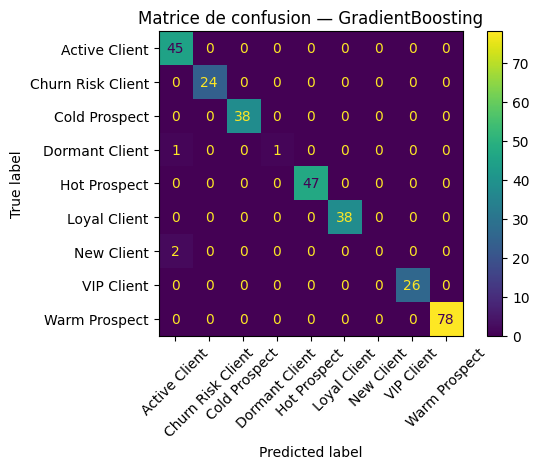

In [42]:
# Matrice de confusion
labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred_best, labels=labels)

plt.figure(figsize=(12, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(xticks_rotation=45, cmap=None, values_format="d")
plt.title(f"Matrice de confusion — {best_model_name}")
plt.tight_layout()
plt.show()


## 9. Importance des variables

Cette section permet d'identifier les variables qui influencent le plus la classification.

Pour un projet de stage, c'est très important pour expliquer le modèle dans le rapport.


In [43]:
# ============================================================
# 9. Feature importance / interpretability
# ============================================================

# Permutation importance: compatible avec tous les modèles sklearn
# Peut prendre quelques secondes.
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="f1_macro"
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values(by="importance_mean", ascending=False)

importance_df.head(20)


,feature,importance_mean,importance_std
18,rfm_score,2.384138e-01,2.534648e-02
20,churn_risk_score,2.294106e-01,1.476855e-02
19,conversion_probability,1.731712e-01,2.142528e-02
8,cart_additions_30d,1.218581e-01,1.146624e-02
6,visits_30d,1.028667e-01,8.235893e-03
9,purchases_90d,9.279941e-02,1.197655e-02
10,total_spent_90d_mad,7.419615e-02,3.412912e-02
15,review_score_avg,1.481481e-03,0.000000e+00
2,behavioral_engagement_score,7.545746e-04,9.241614e-04
27,preferred_category,2.962963e-04,5.925926e-04


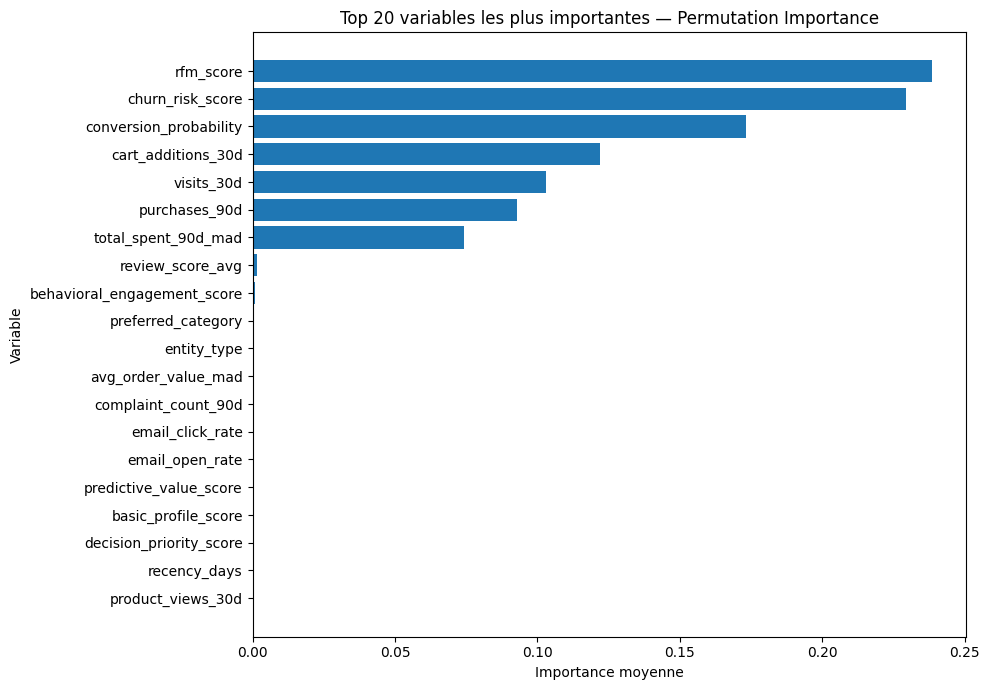

In [44]:
top_n = 20
top_features = importance_df.head(top_n).sort_values("importance_mean")

plt.figure(figsize=(10, 7))
plt.barh(top_features["feature"], top_features["importance_mean"])
plt.title(f"Top {top_n} variables les plus importantes — Permutation Importance")
plt.xlabel("Importance moyenne")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


## 10. Test sur un nouveau prospect/client

Cette cellule montre comment faire une prédiction sur un seul individu.

Tu peux modifier les valeurs pour simuler un nouveau cas.


In [45]:
# ============================================================
# 10. Predict one example
# ============================================================

sample = X_test.iloc[[0]].copy()
prediction = best_model.predict(sample)[0]
proba = None

print("Input example:")
display(sample)

print("\nPredicted dynamic class:", prediction)

if hasattr(best_model.named_steps["model"], "predict_proba"):
    proba_values = best_model.predict_proba(sample)[0]
    classes = best_model.named_steps["model"].classes_

    proba_df = pd.DataFrame({
        "class": classes,
        "probability": proba_values
    }).sort_values(by="probability", ascending=False)

    display(proba_df.head(10))


Input example:


,entity_type,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
279,Prospect,0.651,0.764,0.665,0.691,37,17,59,9,0,0.0,0.0,0.63,0.043,0,NaN,4,0.968,0.0,0.683,0.0,Fès-Meknès,Instagram Ads,Student,Trend Follower,25-34,Mobile,Beauty,True,0.356,0.493,0.802



Predicted dynamic class: Hot Prospect


,class,probability
4,Hot Prospect,9.999991e-01
0,Active Client,8.105281e-07
8,Warm Prospect,6.870517e-08
6,New Client,5.162888e-08
5,Loyal Client,6.759270e-09
2,Cold Prospect,4.343658e-09
7,VIP Client,2.399111e-09
1,Churn Risk Client,2.290908e-09
3,Dormant Client,9.017176e-10


## 11. Associer la classe prédite à une action marketing

Le fichier `osmos_action_rules.csv` contient une action recommandée par classe.

Cette partie permet de transformer la sortie ML en recommandation métier.


In [46]:
# ============================================================
# 11. Recommendation based on predicted class
# ============================================================

rules[["target_class", "recommended_action", "business_goal"]]


,target_class,recommended_action,business_goal
0,Cold Prospect,Continue awareness campaign,Increase brand awareness
1,Warm Prospect,Send educational nurturing campaign,Move prospect toward consideration
2,Hot Prospect,Send limited-time personalized offer,Maximize conversion
3,New Client,Send onboarding sequence,Improve activation
4,Active Client,Send personalized product recommendation,Increase purchase frequency
5,Loyal Client,Suggest cross-sell bundle,Increase basket size
6,VIP Client,Send VIP loyalty reward,Protect high-value clients
7,Dormant Client,Launch reactivation campaign,Recover inactive clients
8,Churn Risk Client,Trigger retention call + personalized compensa...,Reduce churn


In [47]:
def recommend_action(predicted_class, rules_df):
    row = rules_df[rules_df["target_class"] == predicted_class]
    if len(row) == 0:
        return "No action rule found", "No business goal found"

    return (
        row.iloc[0]["recommended_action"],
        row.iloc[0]["business_goal"]
    )

action, goal = recommend_action(prediction, rules)

print("Predicted class:", prediction)
print("Recommended action:", action)
print("Business goal:", goal)


Predicted class: Hot Prospect
Recommended action: Send limited-time personalized offer
Business goal: Maximize conversion


## 12. Simulation simple d'un événement

Exemple : un prospect ajoute un produit au panier.

Dans un vrai système, cet événement mettrait à jour le Behavioral Twin, puis le Predictive Twin, puis la classe finale.

Ici, on montre une simulation simple en modifiant certaines variables, puis en relançant la prédiction.


In [62]:
# ============================================================
# 12. Dynamic event simulation — FIND A CASE THAT CHANGES CLASS
# ============================================================

import numpy as np
import pandas as pd

def apply_event(row):
    simulated = row.copy()

    event_impacts = {
        "visits_30d": 0,
        "product_views_30d": 0,
        "cart_additions_30d": 0,
        "email_click_rate": 0.20,
        "conversion_probability": 0.35,
        "recency_days": -20
    }

    for col, increment in event_impacts.items():
        if col in simulated.columns:
            simulated.loc[:, col] = pd.to_numeric(simulated[col], errors="coerce").fillna(0) + increment

    # recency_days cannot be negative
    if "recency_days" in simulated.columns:
        simulated.loc[:, "recency_days"] = simulated["recency_days"].clip(lower=0)

    # probability columns must stay between 0 and 1
    probability_cols = [
        "email_open_rate",
        "email_click_rate",
        "social_sentiment_avg",
        "conversion_probability",
        "churn_risk_score",
        "behavioral_engagement_score",
        "predictive_value_score",
        "decision_priority_score"
    ]

    for col in probability_cols:
        if col in simulated.columns:
            simulated.loc[:, col] = simulated[col].clip(0, 1)

    # Recalculate Behavioral Twin score
    if "behavioral_engagement_score" in simulated.columns:
        visits = pd.to_numeric(simulated.get("visits_30d", 0), errors="coerce").fillna(0)
        views = pd.to_numeric(simulated.get("product_views_30d", 0), errors="coerce").fillna(0)
        carts = pd.to_numeric(simulated.get("cart_additions_30d", 0), errors="coerce").fillna(0)
        clicks = pd.to_numeric(simulated.get("email_click_rate", 0), errors="coerce").fillna(0)

        simulated.loc[:, "behavioral_engagement_score"] = np.clip(
            (visits / 30) * 0.25 +
            (views / 80) * 0.30 +
            (carts / 10) * 0.30 +
            clicks * 0.15,
            0,
            1
        )

    # Recalculate Predictive Twin score
    if "predictive_value_score" in simulated.columns and "conversion_probability" in simulated.columns:
        conv = pd.to_numeric(simulated["conversion_probability"], errors="coerce").fillna(0)
        rfm = pd.to_numeric(simulated.get("rfm_score", 0), errors="coerce").fillna(0)
        sentiment = pd.to_numeric(simulated.get("social_sentiment_avg", 0), errors="coerce").fillna(0)

        simulated.loc[:, "predictive_value_score"] = np.clip(
            conv * 0.50 + rfm * 0.30 + sentiment * 0.20,
            0,
            1
        )

    # Recalculate Decision Twin score
    if "decision_priority_score" in simulated.columns:
        engagement = pd.to_numeric(simulated.get("behavioral_engagement_score", 0), errors="coerce").fillna(0)
        predictive = pd.to_numeric(simulated.get("predictive_value_score", 0), errors="coerce").fillna(0)
        churn = pd.to_numeric(simulated.get("churn_risk_score", 0), errors="coerce").fillna(0)

        simulated.loc[:, "decision_priority_score"] = np.clip(
            engagement * 0.35 + predictive * 0.45 + churn * 0.20,
            0,
            1
        )

    return simulated


# Try to find a sample where the predicted class changes
changed = False

for i in range(len(X_test)):
    sample = X_test.iloc[[i]].copy()

    before_prediction = best_model.predict(sample)[0]
    simulated = apply_event(sample)
    after_prediction = best_model.predict(simulated)[0]

    if before_prediction != after_prediction:
        changed = True
        break

if not changed:
    print("No class change found with this event. Showing the first sample anyway.")
    sample = X_test.iloc[[0]].copy()
    before_prediction = best_model.predict(sample)[0]
    simulated = apply_event(sample)
    after_prediction = best_model.predict(simulated)[0]

before_action, before_goal = recommend_action(before_prediction, rules)
after_action, after_goal = recommend_action(after_prediction, rules)

cols_to_compare = [
    "recency_days",
    "visits_30d",
    "product_views_30d",
    "cart_additions_30d",
    "email_click_rate",
    "conversion_probability",
    "behavioral_engagement_score",
    "predictive_value_score",
    "decision_priority_score"
]

cols_to_compare = [col for col in cols_to_compare if col in sample.columns]

comparison = pd.DataFrame({
    "variable": cols_to_compare,
    "before": sample[cols_to_compare].iloc[0].values,
    "after": simulated[cols_to_compare].iloc[0].values
})

print("Before class:", before_prediction)
print("Before action:", before_action)

print("\nAfter class:", after_prediction)
print("After action:", after_action)

display(comparison)

print("\nOriginal row:")
display(sample)

print("\nUpdated row after event:")
display(simulated)

Before class: Warm Prospect
Before action: Send educational nurturing campaign

After class: Active Client
After action: Send personalized product recommendation


,variable,before,after
0,recency_days,34.000,14.000000
1,visits_30d,8.000,8.000000
2,product_views_30d,38.000,38.000000
3,cart_additions_30d,3.000,3.000000
4,email_click_rate,0.150,0.350000
5,conversion_probability,0.398,0.748000
6,behavioral_engagement_score,0.388,0.351667
7,predictive_value_score,0.454,0.396600
8,decision_priority_score,0.410,0.301553



Original row:


,entity_type,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
1093,Prospect,0.489,0.388,0.454,0.41,34,8,38,3,0,0.0,0.0,0.445,0.15,0,NaN,0,0.113,0.0,0.398,0.0,Souss-Massa,WhatsApp Campaign,Young Professional,Premium Buyer,35-44,Mobile,Sports,False,0.766,0.692,0.313



Updated row after event:


,entity_type,basic_profile_score,behavioral_engagement_score,predictive_value_score,decision_priority_score,recency_days,visits_30d,product_views_30d,cart_additions_30d,purchases_90d,total_spent_90d_mad,avg_order_value_mad,email_open_rate,email_click_rate,complaint_count_90d,review_score_avg,social_mentions_30d,social_sentiment_avg,rfm_score,conversion_probability,churn_risk_score,region,source_channel,segment,persona,age_group,preferred_device,preferred_category,marketing_consent,price_sensitivity,income_power_score,initial_interest_score
1093,Prospect,0.489,0.351667,0.3966,0.301553,14,8,38,3,0,0.0,0.0,0.445,0.35,0,NaN,0,0.113,0.0,0.748,0.0,Souss-Massa,WhatsApp Campaign,Young Professional,Premium Buyer,35-44,Mobile,Sports,False,0.766,0.692,0.313


## 13. Agrégation optionnelle des événements

Cette section montre comment exploiter le fichier `osmos_events_stream.csv` pour créer des variables comportementales à partir des événements.

Elle est utile pour expliquer la logique **Data Event Driven AI**.


In [49]:
# ============================================================
# 13. Optional: aggregate events by entity
# ============================================================

events["event_time"] = pd.to_datetime(events["event_time"])

event_agg = events.groupby("entity_id").agg(
    total_events=("event_id", "count"),
    total_purchase_value=("value_mad", "sum"),
    conversion_events=("is_conversion_event", "sum"),
    avg_sentiment=("sentiment_score", "mean"),
    unique_channels=("channel", "nunique"),
    unique_categories=("product_category", "nunique")
).reset_index()

event_type_counts = pd.crosstab(events["entity_id"], events["event_type"]).reset_index()

event_features = event_agg.merge(event_type_counts, on="entity_id", how="left")

print("Event features:", event_features.shape)
event_features.head()


Event features: (1304, 12)


,entity_id,total_events,total_purchase_value,conversion_events,avg_sentiment,unique_channels,unique_categories,complaint,email_click,email_open,purchase,review
0,C00002,7,4108.55,3,-0.378878,4,2,1,1,2,3,0
1,C00003,6,3162.57,4,NaN,3,1,0,1,1,4,0
2,C00005,8,2323.58,3,NaN,4,2,0,2,3,3,0
3,C00006,5,2143.88,2,NaN,3,2,0,0,3,2,0
4,C00008,6,4600.04,3,NaN,3,1,0,0,3,3,0


## 14. Sauvegarde du meilleur modèle

Le modèle est sauvegardé au format `.pkl`.

Tu peux ensuite le charger dans une application Streamlit, FastAPI ou un dashboard.


In [50]:
# ============================================================
# 14. Save model
# ============================================================

MODEL_PATH = "osmos_best_dynamic_class_model.pkl"

joblib.dump(best_model, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")


Model saved to: osmos_best_dynamic_class_model.pkl


In [51]:
# Exemple de rechargement
loaded_model = joblib.load(MODEL_PATH)
loaded_prediction = loaded_model.predict(sample)[0]

print("Loaded model prediction:", loaded_prediction)


Loaded model prediction: Hot Prospect


# Conclusion

Ce notebook fournit une première base pour :

1. charger les données simulées OSMOS ;
2. préparer les variables ;
3. entraîner plusieurs modèles ;
4. comparer les performances ;
5. expliquer les variables importantes ;
6. prédire la classe dynamique ;
7. recommander une action marketing ;
8. simuler l'impact d'un événement sur le Digital Twin.

## Améliorations possibles

Pour aller plus loin dans le projet :

- Ajouter XGBoost / LightGBM / CatBoost.
- Ajouter une couche de profilage psychosociologique : Big Five, typologie commerciale.
- Ajouter une simulation A/B testing pour comparer les actions recommandées.
- Ajouter SHAP pour expliquer les prédictions.
- Développer un dashboard Streamlit.
- Mettre en place une API FastAPI pour prédire en temps réel.
